# Week 4 - Day 2
## Practical Task 1 – Basic Probability

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
df = pd.read_csv("Salary_Dataset_with_Extra_Features.csv")

print("Dataset loaded successfully!")

print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (22770, 8)


,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android


In [8]:
contingency_table = pd.crosstab(
    df['Employment Status'],
    df['Job Roles']
)

contingency_table

Job Roles,Android,Backend,Database,Frontend,IOS,Java,Mobile,Python,SDE,Testing,Web
Employment Status,,,,,,,,,,,
Contractor,42,8,56,33,22,60,4,27,133,136,27
Full Time,2669,993,803,1938,1561,1740,229,845,6875,1574,856
Intern,225,193,6,192,47,51,11,69,1166,30,116
Trainee,9,0,0,0,1,7,1,6,9,0,0


In [9]:
A = df['Employment Status'].mode()[0]

B = df['Job Roles'].mode()[0]

clean_df = df.dropna(
    subset=['Employment Status', 'Job Roles']
)

total = len(clean_df)

count_A = (clean_df['Employment Status'] == A).sum()

count_B = (clean_df['Job Roles'] == B).sum()

count_A_and_B = (
    (clean_df['Employment Status'] == A) &
    (clean_df['Job Roles'] == B)
).sum()

P_A = count_A / total

P_B = count_B / total

P_A_and_B = count_A_and_B / total

P_A_given_B = count_A_and_B / count_B

print("Event A:", A)
print("Event B:", B)

print("P(A):", P_A)
print("P(B):", P_B)
print("P(A ∩ B):", P_A_and_B)
print("P(A | B):", P_A_given_B)

Event A: Full Time
Event B: SDE
P(A): 0.881993851559069
P(B): 0.35937637241985065
P(A ∩ B): 0.30193236714975846
P(A | B): 0.8401564218501772


## Practical Task 2 – Normal Distribution

In [10]:
np.random.seed(42)

data = np.random.normal(
    loc=100,
    scale=15,
    size=10000
)

mean = np.mean(data)

std = np.std(data)

print("Mean:", mean)

print("Standard Deviation:", std)

Mean: 99.9679602494736
Standard Deviation: 15.051183091949815


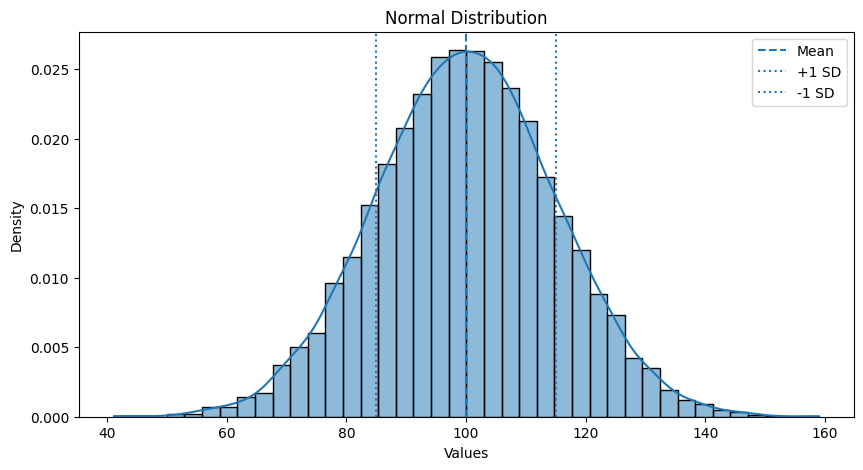

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data,
    bins=40,
    stat='density',
    kde=True
)

plt.axvline(mean, linestyle='--', label='Mean')

plt.axvline(mean + std, linestyle=':', label='+1 SD')

plt.axvline(mean - std, linestyle=':', label='-1 SD')

plt.title('Normal Distribution')

plt.xlabel('Values')

plt.ylabel('Density')

plt.legend()

plt.show()

In [12]:
within_1 = np.mean(
    (data >= mean - std) &
    (data <= mean + std)
) * 100

within_2 = np.mean(
    (data >= mean - 2*std) &
    (data <= mean + 2*std)
) * 100

within_3 = np.mean(
    (data >= mean - 3*std) &
    (data <= mean + 3*std)
) * 100

print("Within 1 SD:", within_1, "%")

print("Within 2 SD:", within_2, "%")

print("Within 3 SD:", within_3, "%")

Within 1 SD: 68.38 %
Within 2 SD: 95.38 %
Within 3 SD: 99.72999999999999 %


## Practical Task 3 – Binomial Distribution

In [13]:
np.random.seed(42)

n = 100

p = 0.30

simulation = np.random.binomial(
    n,
    p,
    size=10000
)

print("Mean conversions:", simulation.mean())

print("Expected conversions:", n * p)

print("Variance:", simulation.var())

Mean conversions: 29.9068
Expected conversions: 30.0
Variance: 20.60391376


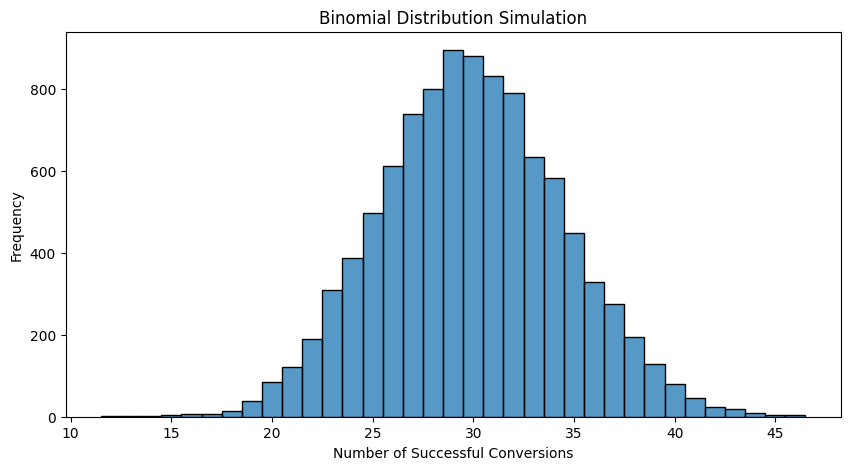

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    simulation,
    bins=25,
    discrete=True
)

plt.title('Binomial Distribution Simulation')

plt.xlabel('Number of Successful Conversions')

plt.ylabel('Frequency')

plt.show()

In [15]:
expected_value = n * p

variance = n * p * (1-p)

std_deviation = np.sqrt(variance)

print("Expected Value:", expected_value)

print("Variance:", variance)

print("Standard Deviation:", std_deviation)

Expected Value: 30.0
Variance: 21.0
Standard Deviation: 4.58257569495584


## Practical Task 4 – Central Limit Theorem (CLT)

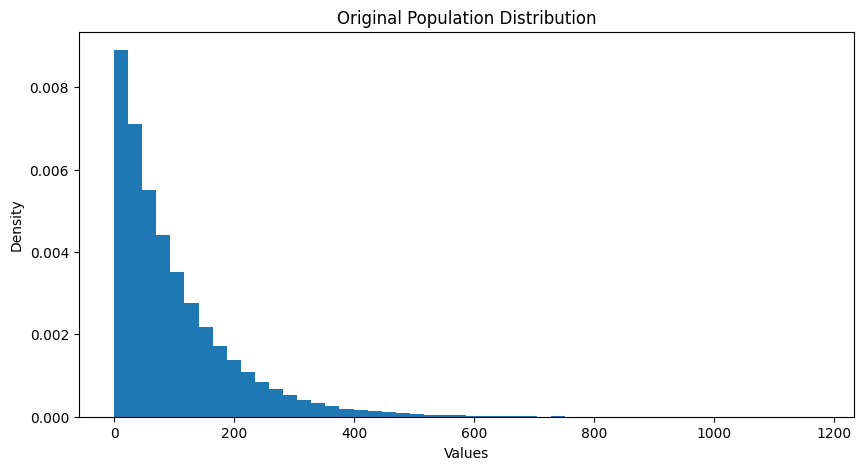

In [16]:
np.random.seed(42)

population = np.random.exponential(
    scale=100,
    size=100000
)

plt.figure(figsize=(10, 5))

plt.hist(
    population,
    bins=50,
    density=True
)

plt.title('Original Population Distribution')

plt.xlabel('Values')

plt.ylabel('Density')

plt.show()

In [17]:
sample_means = []

sample_size = 50

number_of_samples = 1000

for i in range(number_of_samples):

    sample = np.random.choice(
        population,
        size=sample_size
    )

    sample_means.append(sample.mean())

print("Number of sample means:", len(sample_means))

Number of sample means: 1000


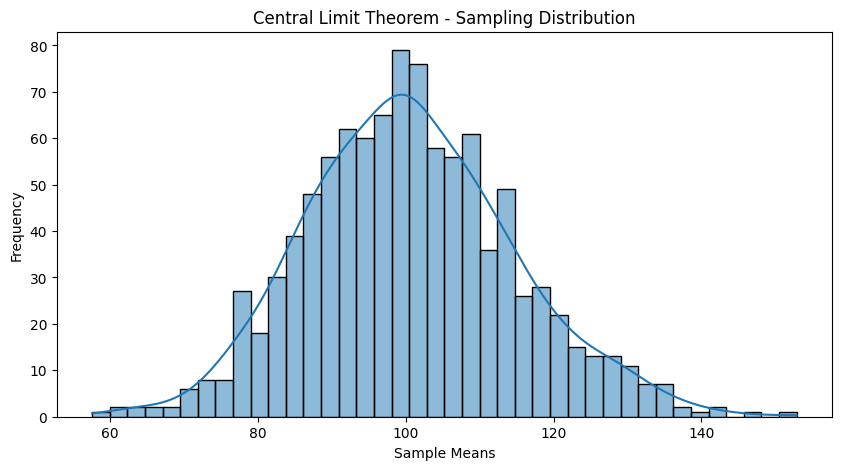

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    sample_means,
    bins=40,
    kde=True
)

plt.title('Central Limit Theorem - Sampling Distribution')

plt.xlabel('Sample Means')

plt.ylabel('Frequency')

plt.show()

In [19]:
print("Population Mean:", population.mean())

print("Mean of Sample Means:", np.mean(sample_means))

print("Standard Deviation of Sample Means:", np.std(sample_means))

print(
    "Theoretical Standard Error:",
    population.std() / np.sqrt(sample_size)
)

Population Mean: 99.59701590561848
Mean of Sample Means: 100.57629805033483
Standard Deviation of Sample Means: 14.043736763676796
Theoretical Standard Error: 14.042702937287107


## Additional Analysis – Probability Visualisation

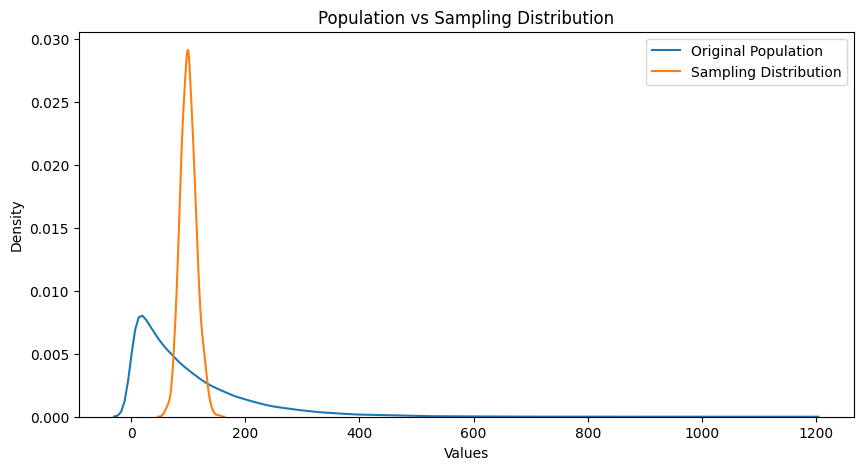

In [20]:
plt.figure(figsize=(10, 5))

sns.kdeplot(
    population,
    label='Original Population'
)

sns.kdeplot(
    sample_means,
    label='Sampling Distribution'
)

plt.title('Population vs Sampling Distribution')

plt.xlabel('Values')

plt.ylabel('Density')

plt.legend()

plt.show()

## Business Insights and Conclusion

## Business Insights
### 1. Conditional probability helps businesses understand the likelihood of an event based on existing conditions.
### 2. Normal distribution helps analyse naturally occurring variations in business measurements.
### 3. The 68-95-99.7 rule helps understand the spread of normally distributed data.
### 4. Binomial distribution helps estimate customer conversions and marketing success rates.
### 5. The Central Limit Theorem explains why sample averages can be used to estimate population averages.
### 6. Sampling simulations reduce the need to repeatedly analyse entire populations.
    
## Conclusion

### This practical helped me understand fundamental probability concepts and their applications in business analytics. I implemented basic probability calculations using contingency tables, visualised normal distributions, simulated binomial distributions using NumPy, and demonstrated the Central Limit Theorem through sampling simulations.